In [11]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt

from tensorflow import keras

from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    GlobalAveragePooling2D
)

from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.optimizers import Adam

print("All libraries imported successfully!")

All libraries imported successfully!


In [12]:
(train_raw, val_raw, test_raw), info = tfds.load(
    "caltech101",
    split=[
        "train[:80%]",
        "train[80%:]",
        "test"
    ],
    as_supervised=True,
    with_info=True
)

print("Caltech-101 Dataset Loaded Successfully!")

print("Training examples:", info.splits["train"].num_examples)

print("Testing examples:", info.splits["test"].num_examples)

Caltech-101 Dataset Loaded Successfully!
Training examples: 3060
Testing examples: 6084


In [13]:
class_names = info.features["label"].names

print("Total Classes:", len(class_names))

print("Available Classes:")

for name in class_names:
    print(name)

Total Classes: 102
Available Classes:
accordion
airplanes
anchor
ant
background_google
barrel
bass
beaver
binocular
bonsai
brain
brontosaurus
buddha
butterfly
camera
cannon
car_side
ceiling_fan
cellphone
chair
chandelier
cougar_body
cougar_face
crab
crayfish
crocodile
crocodile_head
cup
dalmatian
dollar_bill
dolphin
dragonfly
electric_guitar
elephant
emu
euphonium
ewer
faces
faces_easy
ferry
flamingo
flamingo_head
garfield
gerenuk
gramophone
grand_piano
hawksbill
headphone
hedgehog
helicopter
ibis
inline_skate
joshua_tree
kangaroo
ketch
lamp
laptop
leopards
llama
lobster
lotus
mandolin
mayfly
menorah
metronome
minaret
motorbikes
nautilus
octopus
okapi
pagoda
panda
pigeon
pizza
platypus
pyramid
revolver
rhino
rooster
saxophone
schooner
scissors
scorpion
sea_horse
snoopy
soccer_ball
stapler
starfish
stegosaurus
stop_sign
strawberry
sunflower
tick
trilobite
umbrella
watch
water_lilly
wheelchair
wild_cat
windsor_chair
wrench
yin_yang


In [14]:
categories = [
    "airplanes",
    "anchor",
    "ant",
    "barrel",
    "bass"
]

num_classes = len(categories)

selected_labels = [
    class_names.index(name)
    for name in categories
]

print("Selected Categories:", categories)

print("Number of Classes:", num_classes)

print("Selected Label Numbers:", selected_labels)

Selected Categories: ['airplanes', 'anchor', 'ant', 'barrel', 'bass']
Number of Classes: 5
Selected Label Numbers: [1, 2, 3, 5, 6]


In [15]:
selected_labels_tensor = tf.constant(
    selected_labels,
    dtype=tf.int64
)

def filter_categories(image, label):

    return tf.reduce_any(
        tf.equal(label, selected_labels_tensor)
    )


train_raw = train_raw.filter(filter_categories)

val_raw = val_raw.filter(filter_categories)

test_raw = test_raw.filter(filter_categories)

print("Five categories selected successfully!")

Five categories selected successfully!


In [16]:
def convert_labels(image, label):

    matches = tf.equal(
        label,
        selected_labels_tensor
    )

    new_label = tf.argmax(
        tf.cast(matches, tf.int32)
    )

    return image, new_label

In [17]:
def preprocess_data(image, label):

    image = tf.image.resize(
        image,
        (224, 224)
    )

    image = tf.cast(
        image,
        tf.float32
    )

    image = preprocess_input(image)

    label = tf.one_hot(
        label,
        depth=num_classes
    )

    return image, label

In [18]:
train_data = train_raw.map(
    convert_labels,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_data = val_raw.map(
    convert_labels,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_data = test_raw.map(
    convert_labels,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_data = train_data.map(
    preprocess_data,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_data = val_data.map(
    preprocess_data,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_data = test_data.map(
    preprocess_data,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_data = train_data.batch(32)

val_data = val_data.batch(32)

test_data = test_data.batch(32)

train_data = train_data.prefetch(tf.data.AUTOTUNE)

val_data = val_data.prefetch(tf.data.AUTOTUNE)

test_data = test_data.prefetch(tf.data.AUTOTUNE)

print("Dataset preprocessing completed!")

Dataset preprocessing completed!


In [19]:
for images, labels in train_data.take(1):

    print("Training Image Shape:", images.shape)

    print("Training Label Shape:", labels.shape)


for images, labels in test_data.take(1):

    print("Testing Image Shape:", images.shape)

    print("Testing Label Shape:", labels.shape)

Training Image Shape: (32, 224, 224, 3)
Training Label Shape: (32, 5)
Testing Image Shape: (32, 224, 224, 3)
Testing Label Shape: (32, 5)


I0000 00:00:1794750019.119749   97165 tf_record_dataset_op.cc:396] The default buffer size is 262144, which is overridden by the user specified `buffer_size` of 8388608
W0000 00:00:1794750019.178913   97170 cache_dataset_ops.cc:912] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
W0000 00:00:1794750019.257514   97257 cache_dataset_ops.cc:912] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


W0000 00:00:1794750026.686709   97358 cache_dataset_ops.cc:912] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


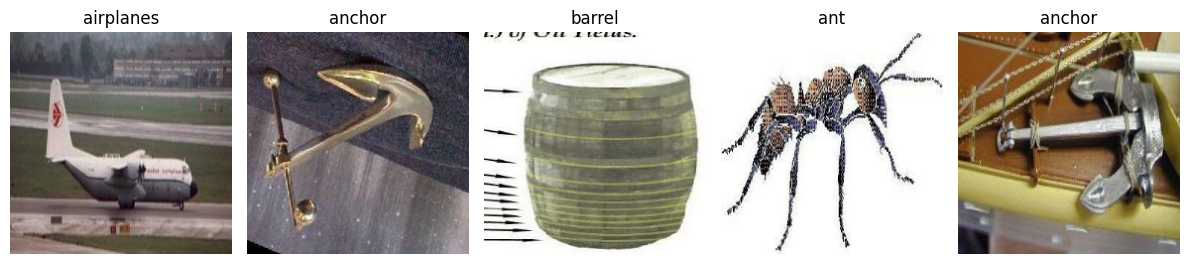

In [20]:
for images, labels in train_data.take(1):

    plt.figure(figsize=(12, 6))

    for i in range(min(5, len(images))):

        img = images[i].numpy().copy()

        img += [103.939, 116.779, 123.68]

        img = img[..., ::-1]

        img = np.clip(img, 0, 255).astype("uint8")

        label = np.argmax(labels[i].numpy())

        plt.subplot(1, 5, i + 1)

        plt.imshow(img)

        plt.title(categories[label])

        plt.axis("off")

    plt.tight_layout()

    plt.show()

In [21]:
base_model22 = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

print("VGG16 Model Loaded Successfully!")

VGG16 Model Loaded Successfully!


In [22]:
base_model22.trainable = False

print("All VGG16 layers are frozen!")

All VGG16 layers are frozen!


In [23]:
input_layer = Input(shape=(224, 224, 3))

x = base_model22(input_layer)

x = GlobalAveragePooling2D()(x)

x = Dense(256, activation="relu")(x)

x = Dropout(0.5)(x)

output_layer = Dense(
    num_classes,
    activation="softmax"
)(x)

model22 = Model(
    inputs=input_layer,
    outputs=output_layer
)

model22.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,847,301 (56.64 MB)

 Trainable params: 132,613 (518.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [24]:
model22.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model Compiled Successfully!")

Model Compiled Successfully!


In [25]:
history22 = model22.fit(
    train_data,
    epochs=10,
    validation_data=val_data
)

Epoch 1/10


/home/najanrohit0/.local/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


      4/Unknown 13s 3s/step - accuracy: 0.2720 - loss: 6.3291

/home/najanrohit0/.local/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


4/4 ━━━━━━━━━━━━━━━━━━━━ 15s 3s/step - accuracy: 0.2720 - loss: 6.3291 - val_accuracy: 0.6400 - val_loss: 1.9235
Epoch 2/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 10s 3s/step - accuracy: 0.6800 - loss: 2.0136 - val_accuracy: 0.8400 - val_loss: 0.4325
Epoch 3/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 10s 3s/step - accuracy: 0.8400 - loss: 0.8995 - val_accuracy: 0.8800 - val_loss: 0.2274
Epoch 4/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 11s 3s/step - accuracy: 0.9040 - loss: 0.2994 - val_accuracy: 0.9600 - val_loss: 0.0909
Epoch 5/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 11s 3s/step - accuracy: 0.9280 - loss: 0.2126 - val_accuracy: 0.9600 - val_loss: 0.1237
Epoch 6/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 11s 3s/step - accuracy: 0.9520 - loss: 0.1244 - val_accuracy: 0.8400 - val_loss: 0.1981
Epoch 7/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 11s 3s/step - accuracy: 0.9760 - loss: 0.0371 - val_accuracy: 0.8000 - val_loss: 0.2160
Epoch 8/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 12s 3s/step - accuracy: 0.9920 - loss: 0.0167 - val_accuracy: 0.8400 - val_loss: 0.1926
Epoch 9/10
4/4 ━━━━

In [26]:
loss22, accuracy22 = model22.evaluate(test_data)

print("Test Loss:", loss22)

print("Test Accuracy:", accuracy22 * 100, "%")

27/27 ━━━━━━━━━━━━━━━━━━━━ 63s 2s/step - accuracy: 0.9844 - loss: 0.0616
Test Loss: 0.06162920221686363
Test Accuracy: 98.44311475753784 %


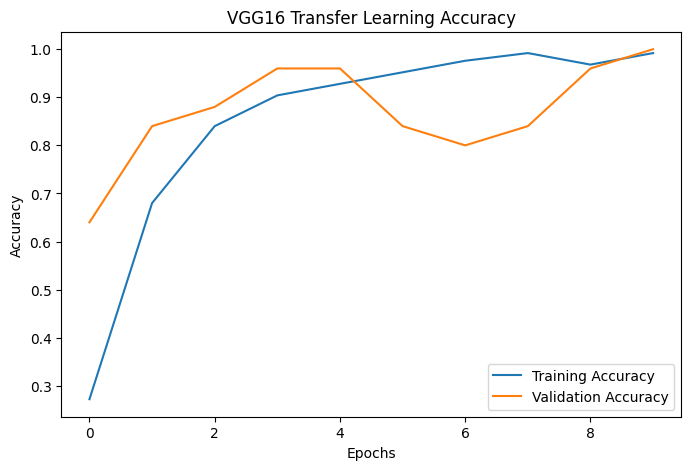

In [27]:
plt.figure(figsize=(8, 5))

plt.plot(
    history22.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history22.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("VGG16 Transfer Learning Accuracy")

plt.xlabel("Epochs")

plt.ylabel("Accuracy")

plt.legend()

plt.show()

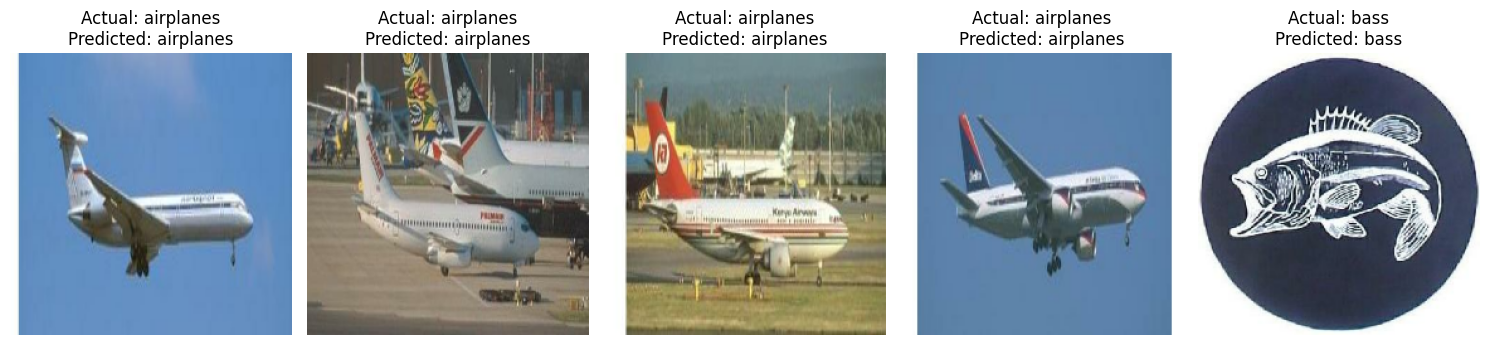

In [28]:
for images, labels in test_data.take(1):

    predictions = model22.predict(
        images,
        verbose=0
    )

    plt.figure(figsize=(15, 5))

    for i in range(min(5, len(images))):

        actual = np.argmax(labels[i].numpy())

        predicted = np.argmax(predictions[i])

        img = images[i].numpy().copy()

        img += [103.939, 116.779, 123.68]

        img = img[..., ::-1]

        img = np.clip(img, 0, 255).astype("uint8")

        plt.subplot(1, 5, i + 1)

        plt.imshow(img)

        plt.title(
            "Actual: " + categories[actual] +
            "\nPredicted: " + categories[predicted]
        )

        plt.axis("off")

    plt.tight_layout()

    plt.show()

In [29]:
#26

In [30]:
base_model26 = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model26.trainable = False

feature_extractor = Sequential([

    base_model26,

    GlobalAveragePooling2D()

])

print("Feature Extractor Created!")

Feature Extractor Created!


In [31]:
X_train_features = feature_extractor.predict(
    train_data,
    verbose=1
)

print("Training Features:", X_train_features.shape)

4/4 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step
Training Features: (125, 512)


In [32]:
X_val_features = feature_extractor.predict(
    val_data,
    verbose=1
)

print("Validation Features:", X_val_features.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Validation Features: (25, 512)


In [33]:
X_test_features = feature_extractor.predict(
    test_data,
    verbose=1
)

print("Testing Features:", X_test_features.shape)

27/27 ━━━━━━━━━━━━━━━━━━━━ 66s 2s/step
Testing Features: (835, 512)


In [34]:
y_train = np.concatenate([
    labels.numpy()
    for images, labels in train_data
])

y_val = np.concatenate([
    labels.numpy()
    for images, labels in val_data
])

y_test = np.concatenate([
    labels.numpy()
    for images, labels in test_data
])

print("Training Labels:", y_train.shape)

print("Validation Labels:", y_val.shape)

print("Testing Labels:", y_test.shape)

Training Labels: (125, 5)
Validation Labels: (25, 5)
Testing Labels: (835, 5)


In [35]:
classifier26 = Sequential([

    Input(shape=(512,)),

    Dense(
        num_classes,
        activation="softmax"
    )

])

classifier26.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 5)              │         2,565 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,565 (10.02 KB)

 Trainable params: 2,565 (10.02 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
classifier26.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Classifier Compiled!")

Classifier Compiled!


In [37]:
history26 = classifier26.fit(
    X_train_features,
    y_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_val_features, y_val)
)

Epoch 1/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.2000 - loss: 8.5858 - val_accuracy: 0.1200 - val_loss: 8.2870
Epoch 2/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.2640 - loss: 5.8497 - val_accuracy: 0.2000 - val_loss: 6.6485
Epoch 3/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.3280 - loss: 4.3871 - val_accuracy: 0.2400 - val_loss: 5.6839
Epoch 4/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4640 - loss: 3.2130 - val_accuracy: 0.3200 - val_loss: 4.7245
Epoch 5/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6000 - loss: 2.2574 - val_accuracy: 0.4000 - val_loss: 3.8749
Epoch 6/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6560 - loss: 1.4988 - val_accuracy: 0.4400 - val_loss: 3.2060
Epoch 7/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7600 - loss: 1.0514 - val_accuracy: 0.4800 - val_loss: 2.6889
Epoch 8/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8560 - loss: 0.6626 - val_accuracy: 0.6800 - val_loss: 2.3601


In [38]:
loss26, accuracy26 = classifier26.evaluate(
    X_test_features,
    y_test
)

print("Test Loss:", loss26)

print("Test Accuracy:", accuracy26 * 100, "%")

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8814 - loss: 0.3926 
Test Loss: 0.39255374670028687
Test Accuracy: 88.14371228218079 %


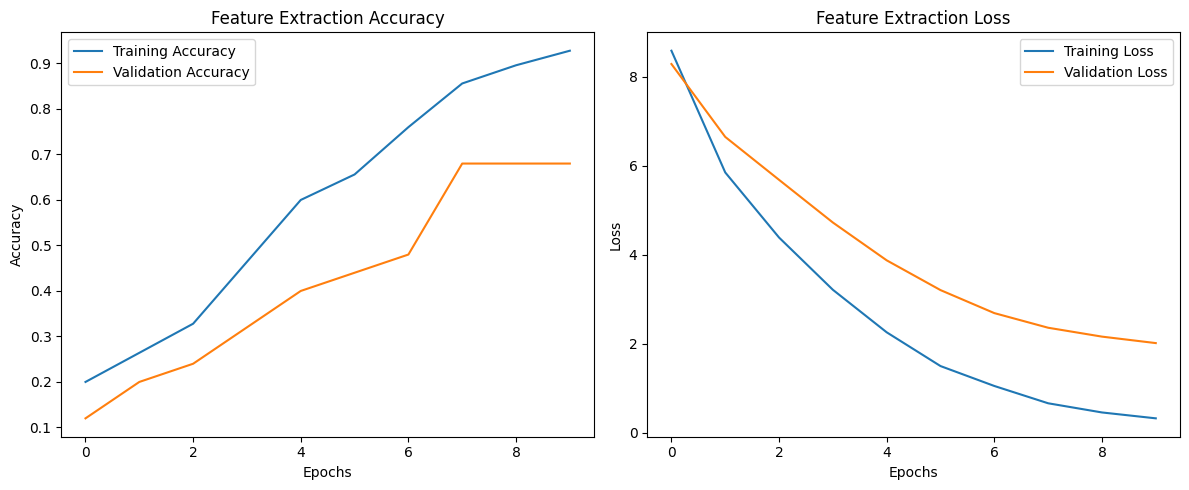

In [39]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(
    history26.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history26.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Feature Extraction Accuracy")

plt.xlabel("Epochs")

plt.ylabel("Accuracy")

plt.legend()

plt.subplot(1, 2, 2)

plt.plot(
    history26.history["loss"],
    label="Training Loss"
)

plt.plot(
    history26.history["val_loss"],
    label="Validation Loss"
)

plt.title("Feature Extraction Loss")

plt.xlabel("Epochs")

plt.ylabel("Loss")

plt.legend()

plt.tight_layout()

plt.show()

In [40]:
#27

In [41]:
base_model27 = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

print("VGG16 Model Loaded!")

VGG16 Model Loaded!


In [42]:
base_model27.trainable = True

for layer in base_model27.layers:

    if layer.name.startswith("block5_conv"):

        layer.trainable = True

    else:

        layer.trainable = False

print("Lower layers frozen!")

for layer in base_model27.layers:

    print(layer.name, layer.trainable)

Lower layers frozen!
input_layer_7 False
block1_conv1 False
block1_conv2 False
block1_pool False
block2_conv1 False
block2_conv2 False
block2_pool False
block3_conv1 False
block3_conv2 False
block3_conv3 False
block3_pool False
block4_conv1 False
block4_conv2 False
block4_conv3 False
block4_pool False
block5_conv1 True
block5_conv2 True
block5_conv3 True
block5_pool False


In [43]:
input_layer = Input(shape=(224, 224, 3))

x = base_model27(input_layer)

x = GlobalAveragePooling2D()(x)

x = Dense(256, activation="relu")(x)

x = Dense(128, activation="relu")(x)

x = Dropout(0.5)(x)

output_layer = Dense(
    num_classes,
    activation="softmax"
)(x)

model27 = Model(
    inputs=input_layer,
    outputs=output_layer
)

model27.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,879,557 (56.76 MB)

 Trainable params: 7,244,293 (27.63 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

In [44]:
model27.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model Compiled Successfully!")

Model Compiled Successfully!


In [45]:
history27 = model27.fit(
    train_data,
    epochs=10,
    validation_data=val_data
)

Epoch 1/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 17s 4s/step - accuracy: 0.2480 - loss: 3.4440 - val_accuracy: 0.4000 - val_loss: 1.4134
Epoch 2/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 13s 3s/step - accuracy: 0.5120 - loss: 1.2957 - val_accuracy: 0.5600 - val_loss: 1.1563
Epoch 3/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 13s 3s/step - accuracy: 0.7200 - loss: 0.7492 - val_accuracy: 0.6400 - val_loss: 0.9516
Epoch 4/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 13s 3s/step - accuracy: 0.8160 - loss: 0.5001 - val_accuracy: 0.7600 - val_loss: 0.6093
Epoch 5/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 12s 3s/step - accuracy: 0.9200 - loss: 0.3069 - val_accuracy: 0.7600 - val_loss: 0.4385
Epoch 6/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 16s 4s/step - accuracy: 0.9280 - loss: 0.2004 - val_accuracy: 0.8400 - val_loss: 0.3527
Epoch 7/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 12s 3s/step - accuracy: 0.9440 - loss: 0.1750 - val_accuracy: 0.8400 - val_loss: 0.2805
Epoch 8/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 12s 3s/step - accuracy: 0.9760 - loss: 0.1224 - val_accuracy: 0.9600 - val_loss: 0.2161
Epoch 9/

In [46]:
loss27, accuracy27 = model27.evaluate(test_data)

print("Test Loss:", loss27)

print("Test Accuracy:", accuracy27 * 100, "%")

27/27 ━━━━━━━━━━━━━━━━━━━━ 64s 2s/step - accuracy: 0.9928 - loss: 0.0203
Test Loss: 0.020315077155828476
Test Accuracy: 99.28143620491028 %


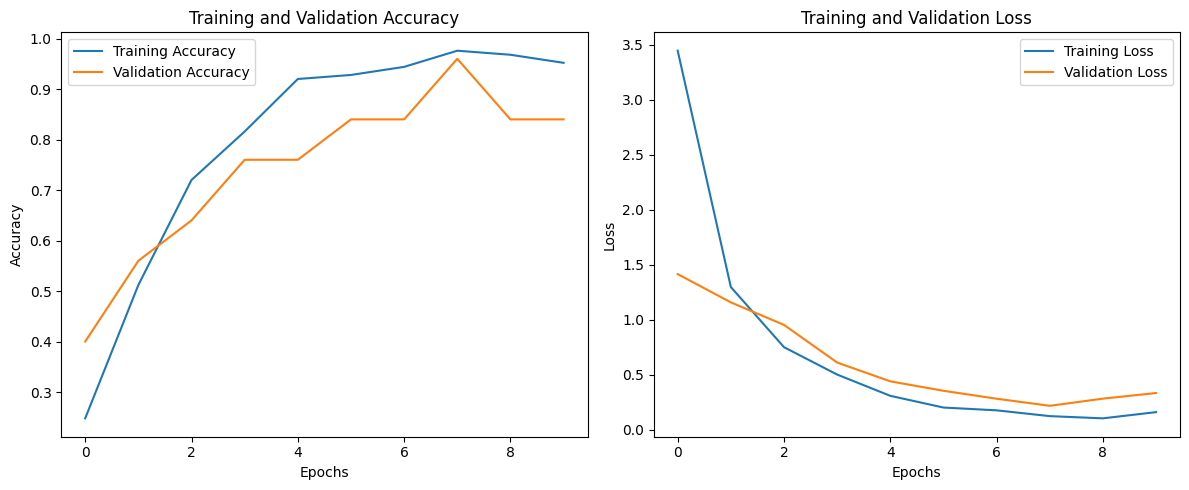

In [47]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(
    history27.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history27.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training and Validation Accuracy")

plt.xlabel("Epochs")

plt.ylabel("Accuracy")

plt.legend()

plt.subplot(1, 2, 2)

plt.plot(
    history27.history["loss"],
    label="Training Loss"
)

plt.plot(
    history27.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training and Validation Loss")

plt.xlabel("Epochs")

plt.ylabel("Loss")

plt.legend()

plt.tight_layout()

plt.show()

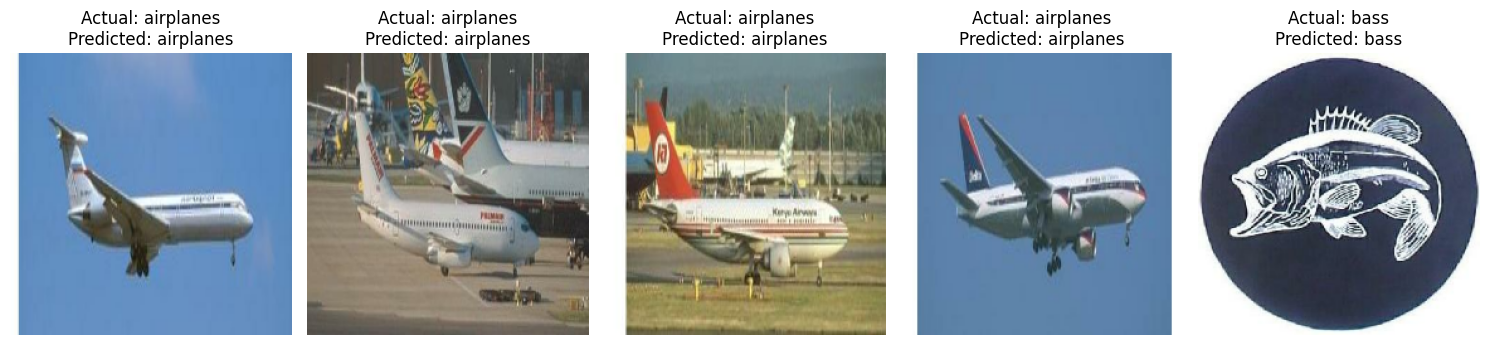

In [48]:
for images, labels in test_data.take(1):

    predictions = model27.predict(
        images,
        verbose=0
    )

    plt.figure(figsize=(15, 5))

    for i in range(min(5, len(images))):

        actual = np.argmax(labels[i].numpy())

        predicted = np.argmax(predictions[i])

        img = images[i].numpy().copy()

        img += [103.939, 116.779, 123.68]

        img = img[..., ::-1]

        img = np.clip(img, 0, 255).astype("uint8")

        plt.subplot(1, 5, i + 1)

        plt.imshow(img)

        plt.title(
            "Actual: " + categories[actual] +
            "\nPredicted: " + categories[predicted]
        )

        plt.axis("off")

    plt.tight_layout()

    plt.show()